In [1]:
using LinearAlgebra
using DifferentialEquations
using Plots
using Statistics
using HypothesisTests
gr();

In [2]:
## firing rate params
theta_F = 0.2 # sigmoid threshold
k_F = 12 # sigmoid slope

## input params
lambda_2 = 1/6 # plataeu fraction
alpha_1 = 0.015 # impulse rise time, secs
alpha_2 = 0.0825 # plataeu stay time, secs
I_p = 0.47 # input amplitude 
sigma_p = 4.25 # lateral input decay 

## intrinsic 
g = 0.065 # adaptation strength
gamma = 0.075 # noise level
beta_i = 0.3 # inhibition strength
#sigma_i = 10
beta_e =  0.85 # recurrent excitation strength 
kappa = .25 # excitation decay strength

## timescales (seconds)
tau_r = 0.010 # cortical
tau_a = 1.4 # adaptation
tau_e = 0.070 # NMDA excitation
tau_chi = 0.1 # noise 
tau_d = 3; # excitation decay 

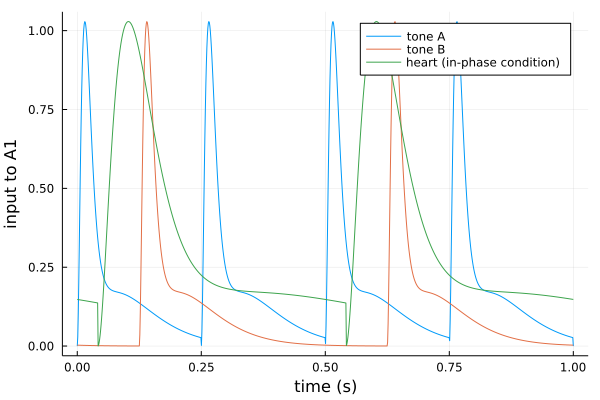

In [3]:
PR = 8
period_A = (100/PR)*2 / 100
period_B = 2*period_A 

function H(t) # Heaviside function
    if t > 0
        out = 1
    elseif t == 0
        out = .5
    else
        out = 0
    end
    out # return  
end

function I(t) 
    # input as a function of time after last onset, meant to mimic primate A1 responses from Micheyl (2005)
    # Note: Rankin et al (2015) leave out a negative sign, but it's in github.com/james-rankin/auditory-streaming
    H(t)*exp(2)/(alpha_1^2) * (t^2)*exp(-2*abs(t)/alpha_1) + lambda_2*H(t)*exp(2)/(alpha_2^2) * (t^2)*exp(-2*abs(t)/alpha_2)
end


function t_A(t) # time from last A tone onset
    t - floor(t/period_A) * period_A 
end

function t_B(t)
    t - floor((t - period_A/2)/period_B)*period_B - period_A/2
end

function t_heart(t)
    t_B(t + period_B/2)
end

function I_A(t) # cortical input for A tone
    I(t_A(t))
end

function I_B(t) # cortical input for B tone
    I(t_B(t)) 
end

function I_heart_antiphase(t)
    I(t_heart(t + period_B/6)/4)
end

function I_heart_inphase(t)
    I(t_B(t + period_B/6)/4)
end


t = collect(range(0, 1, length = 1000))
plot(t, I_A.(t), label =  "tone A", xlabel = "time (s)", ylabel = "input to A1")
plot!(t, I_B.(t), label = "tone B")
#plot!(t, I_heart_inphase.(t), label = "heart in-phase")
plot!(t, I_heart_inphase.(t), label = "heart (in-phase condition)")

In [4]:
function F(u) # firing rate function with threshold theta and slope k
    1 / ( 1 + exp(k_F * (-u + theta_F)) )
end


function w(delta_f) # spread of input across auditory tonotopy 
    I_p * exp(-delta_f/sigma_p)
end

function C_i(delta_f) # global inhibition
    beta_i/2 # less than orig model cause we added cardiac inhibition
    # and things get a bit wacky with too much inhibition
end

function cortex!(du, u, p, t)

    # unpack static parameters
    delta_f, in_phase = p
        
    # unpack dynamic parameters 
    r_AB, r_A, r_B, a_AB, a_A, a_B, e_AB, e_A, e_B, d_AB, d_A, d_B, chi_AB, chi_A, chi_B = u

    if in_phase
        heart = I_heart_inphase(t) * beta_i # inhibition aligned with B 
        i_B = 0.5*I_B(t)# and B can also be attenuated directly
    else
        heart = I_heart_antiphase(t) * beta_i
        i_B = I_B(t)
    end

    ## population responses for units AB, A, and B, respectively 
    du[1] = (-r_AB + F( # firing rate is a function of....
            beta_e*d_AB*e_AB # recurrent excitation,
            - C_i(0)*r_AB # recurrent inhibition,
            - C_i(delta_f/2)*(r_A + r_B) # lateral inhibition,
            - g*a_AB # adaptation,
            + w(delta_f/2)*I_A(t) + w(delta_f/2)*i_B # tonotopic inputs,
            + chi_AB # and noise
            - heart) # plus new term for cardiac inhibition
        ) / tau_r
    du[2] = (-r_A + F(beta_e*d_A*e_A - C_i(0)*r_A - C_i(delta_f)*r_B - 2*C_i(delta_f/2)*r_AB 
            - g*a_A + w(0)*I_A(t) + w(delta_f)*i_B + chi_A - heart))/tau_r
    du[3] = (-r_B + F(beta_e*d_B*e_B - C_i(0)*r_B - C_i(delta_f)*r_A - 2*C_i(delta_f/2)*r_AB 
            - g*a_B + w(delta_f)*I_A(t) + w(0)*i_B + chi_B - heart))/tau_r

    ## adaptation 
    du[4] = (-a_AB + r_AB)/tau_a
    du[5] = (-a_A + r_A)/tau_a
    du[6] = (-a_B + r_B)/tau_a

    ## NMDA excitation
    du[7] = (-e_AB + r_AB)/tau_e
    du[8] = (-e_A + r_A)/tau_e
    du[9] = (-e_B + r_B)/tau_e

    ## excitation decay 
    du[10] = (-d_AB + (1 - kappa*r_AB))/tau_d
    du[11] = (-d_A + (1 - kappa*r_A))/tau_d
    du[12] = (-d_B + (1 - kappa*r_B))/tau_d

    ## Ornstien-Uhlenbeck noise process
    # (NOTE: mismatch between Rankin paper and github.com/james-rankin/auditory-streaming)
    du[13] = -chi_AB/tau_chi
    du[14] = -chi_A/tau_chi # + gamma*sqrt(2/tau_chi)*N(0, dt) implicit 
    du[15] = -chi_B/tau_chi

end


function noise_var!(du, u, p, t)
    for i in 1:12
        du[i] = 0
    end
    for i in 13:15 # standard deviation of white noise
        # over which to integrate for noise process
        du[i] = gamma * sqrt(2/tau_chi)
    end
end


u0 = zeros(15) # inital values for simulation
u0[1] = .6
u0[7:9] = [.3, .3, .3]
u0[10:12] = [1, 1, 1]
tspan = (1, 11) # in seconds
p = (5, true)
model = SDEProblem(cortex!, noise_var!, u0, tspan, p, saveat = 0.001);

0.7776222377762224

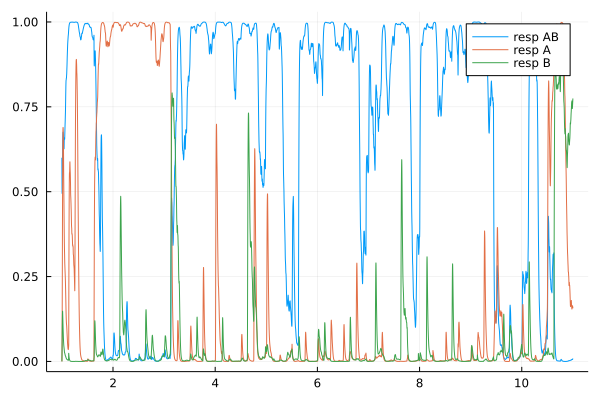

In [5]:
seed = 1
sol = solve(model, p = (5, false), seed = seed)
r_AB = [u[1] for u in sol.u]
r_A = [u[2] for u in sol.u]
r_B = [u[3] for u in sol.u]
coherent = r_AB .>= ((r_A .+ r_B)./2)
t = sol.t

print(mean(coherent))

plot(t, r_AB, label = "resp AB")
plot!(t, r_A, label = "resp A")
plot!(t, r_B, label = "resp B")

0.33596640335966405

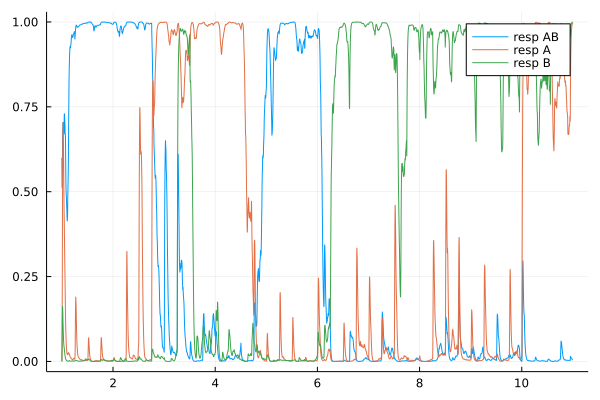

In [6]:
sol = solve(model, p = (5, true), seed = seed)
r_AB = [u[1] for u in sol.u]
r_A = [u[2] for u in sol.u]
r_B = [u[3] for u in sol.u]
coherent = r_AB .>= ((r_A .+ r_B)./2)
t = sol.t

print(mean(coherent))

plot(t, r_AB, label = "resp AB")
plot!(t, r_A, label = "resp A")
plot!(t, r_B, label = "resp B")

In [7]:
function simulation(in_phase, seed)
    sol = solve(model, p = (5, in_phase), seed = seed)
    r_AB = [u[1] for u in sol.u]
    r_A = [u[2] for u in sol.u]
    r_B = [u[3] for u in sol.u]
    coherent = r_AB .>= ((r_A .+ r_B)./2)
    mean(coherent)
end

n_sims = 1000
systole = [simulation(true, i) for i in 1:n_sims]
diastole = [simulation(false, i) for i in 1:n_sims];

In [8]:
mean(systole)

0.44991230876912314

In [9]:
mean(diastole)

0.4814559544045595

In [10]:
mean(systole .< diastole) # proportion systole < diastole

0.569

In [11]:
OneSampleTTest(systole .- diastole)

One sample t-test
-----------------
Population details:
    parameter of interest:   Mean
    value under h_0:         0
    point estimate:          -0.0315436
    95% confidence interval: (-0.04386, -0.01923)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-06

Details:
    number of observations:   1000
    t-statistic:              -5.027012122899619
    degrees of freedom:       999
    empirical standard error: 0.006274829832167153


In [12]:
UnequalVarianceTTest(systole, diastole)

Two sample t-test (unequal variance)
------------------------------------
Population details:
    parameter of interest:   Mean difference
    value under h_0:         0
    point estimate:          -0.0315436
    95% confidence interval: (-0.04484, -0.01825)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-05

Details:
    number of observations:   [1000,1000]
    t-statistic:              -4.653795776863729
    degrees of freedom:       1974.2068699526378
    empirical standard error: 0.006778046813367942


In [14]:
mean(systole .> .5)

0.391

In [15]:
mean(diastole .> .5)

0.462

In [16]:
using JLD
save("systole.jld", "systole", systole)
save("diastole.jld", "diastole", diastole)